# Professional Invisibility Cloak

# 1. Camera Test & Setup Block

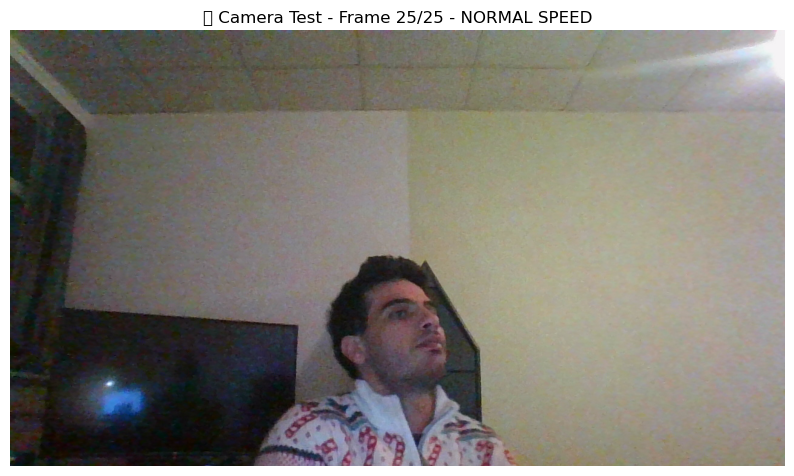

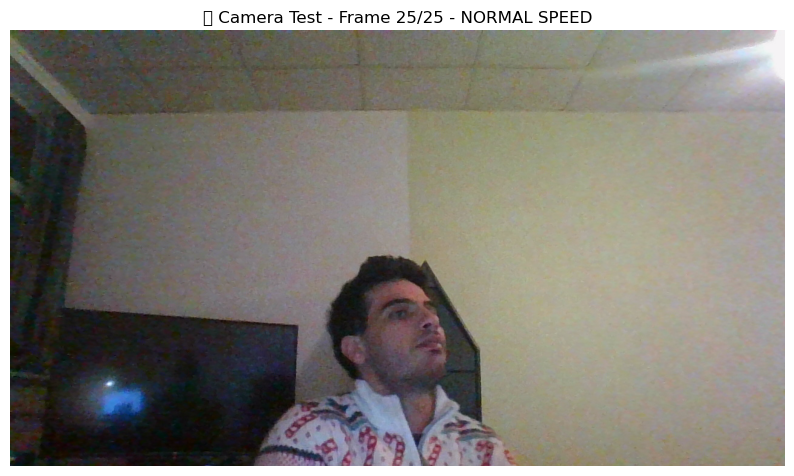

📊 Camera test completed: 25 frames, 1.0 FPS


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import datetime
import time
import os

print("INITIALIZING PROFESSIONAL INVISIBILITY CLOAK")
print("=" * 50)

def test_camera():
    cap = cv2.VideoCapture(0)
    
    if not cap.isOpened():
        print("Camera not accessible. Please check:")
        print(" - Camera is connected")
        print(" - No other app is using the camera")
        print(" - Camera permissions are granted")
        return None
    
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
    
    print("Camera detected! Testing feed...")
    print("Displaying at NORMAL speed...")
    
    frame_count = 0
    start_time = time.time()
    
    try:
        for i in range(25): 
            ret, frame = cap.read()
            if ret:
                frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                frame_count += 1
                
                clear_output(wait=True)
                plt.figure(figsize=(10, 6))
                plt.imshow(frame_rgb)
                plt.title(f"📹 Camera Test - Frame {i+1}/25 - NORMAL SPEED")
                plt.axis('off')
                display(plt.gcf())
            
         
            time.sleep(0.1)  
            plt.pause(0.1) 
            
    except Exception as e:
        print(f"Camera test error: {e}")
        return None
    finally:
        cap.release()
        plt.close('all')
    
    elapsed = time.time() - start_time
    fps = frame_count / elapsed if elapsed > 0 else 0
    
    print(f"📊 Camera test completed: {frame_count} frames, {fps:.1f} FPS")
    return True

camera_ok = test_camera()

# 2. Background Capture Block

C:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


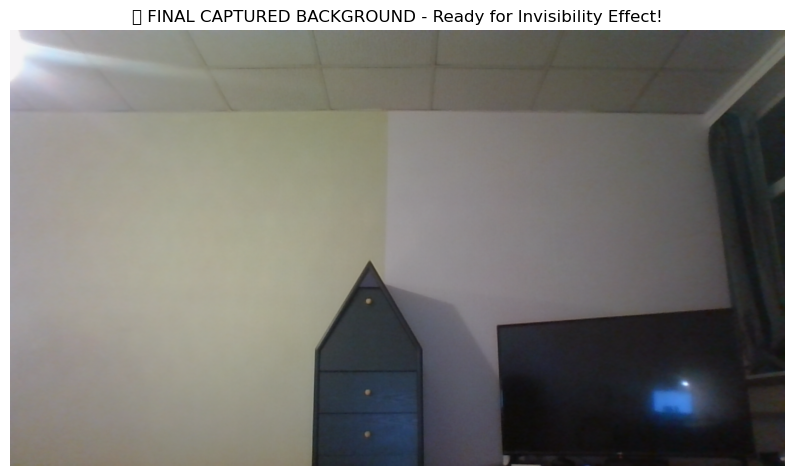

In [2]:
def capture_background():
    cap = cv2.VideoCapture(0)
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
    
    print("\n CAPTURING BACKGROUND")
    print("Please ensure:")
    print("   - No one is in front of the camera")
    print("   - Lighting is consistent")
    print("   - Background is static")
    print("=" * 40)
    
    print("Adjusting camera for 3 seconds...")
    for i in range(3, 0, -1):
        print(f"Starting in {i}...")
        time.sleep(1)  
    
    print("Capturing 30 background frames at NORMAL speed...")
    background_frames = []
    
    for i in range(30):
        ret, frame = cap.read()
        if ret:
            frame = cv2.flip(frame, 1) 
            background_frames.append(frame)
        
       
        if (i + 1) % 5 == 0:  
            clear_output(wait=True)
            progress = (i + 1) / 30 * 100
            print(f"📸 Capturing background: {i + 1}/30 frames ({progress:.0f}%)")
            print("⏱️  Processing at NORMAL speed...")
            
            if background_frames:
                sample_frame = cv2.cvtColor(background_frames[-1], cv2.COLOR_BGR2RGB)
                plt.figure(figsize=(12, 5))
                
                plt.subplot(1, 2, 1)
                plt.imshow(sample_frame)
                plt.title("Current Background View")
                plt.axis('off')
                
                plt.subplot(1, 2, 2)
                plt.barh(['Progress'], [progress], color='green', alpha=0.7)
                plt.xlim(0, 100)
                plt.title(f"Capture Progress: {progress:.0f}%")
                plt.tight_layout()
                display(plt.gcf())
        
     
        time.sleep(0.15)  
        plt.pause(0.15)
    
    if not background_frames:
        print("❌ Failed to capture any background frames!")
        cap.release()
        return None, None
    

    background = np.median(background_frames, axis=0).astype(np.uint8)
    
    print("✅ Background captured successfully!")
    print(f"📏 Resolution: {background.shape[1]}x{background.shape[0]}")
    
   
    clear_output(wait=True)
    background_rgb = cv2.cvtColor(background, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10, 6))
    plt.imshow(background_rgb)
    plt.title("🎯 FINAL CAPTURED BACKGROUND - Ready for Invisibility Effect!")
    plt.axis('off')
    plt.show()
    
    return cap, background

# Capture background
cap, background = capture_background()

# 3. Main Invisibility Effect with Perfect Speed Control

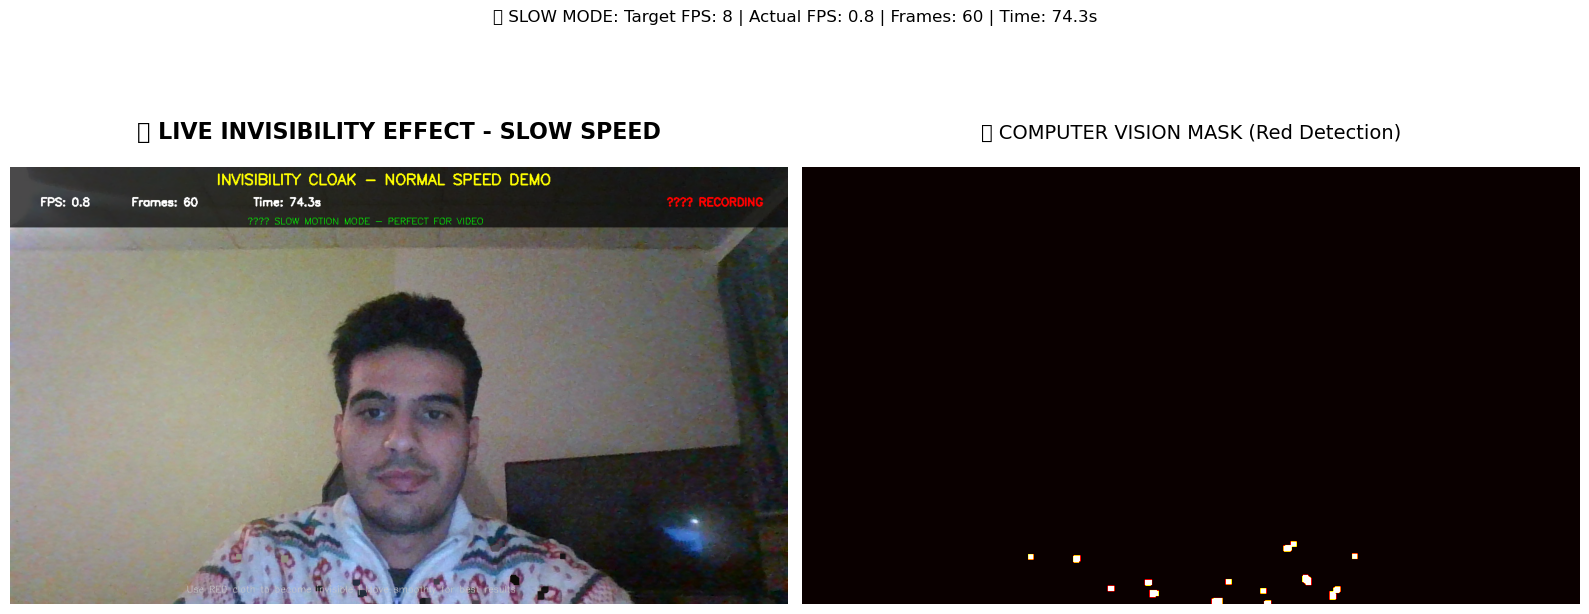

⏱️  Frame 60: Processing took 0.531s, Delaying 0.080s

🛑 Demo stopped by user

📊 SLOW SPEED DEMO COMPLETED SUCCESSFULLY!
🎥 Video saved: invisibility_cloak_slow_20251127_213128.mp4
📏 Resolution: 1280x720
⏱️  Duration: 78.0 seconds
📊 Frames processed: 60
🐢 Average FPS: 0.8
⭐ VIDEO IS NOW AT PERFECT SLOW SPEED ⭐


In [3]:
class ProfessionalInvisibilityCloak:
    def __init__(self, background):
        self.background = background
        self.recording = False
        self.video_writer = None
        
    def setup_color_detection(self, color='red'):
        if color.lower() == 'red':
            self.lower_red1 = np.array([0, 120, 70])   
            self.upper_red1 = np.array([15, 255, 255])  
            self.lower_red2 = np.array([160, 120, 70]) 
            self.upper_red2 = np.array([180, 255, 255]) 
        
    def create_enhanced_mask(self, frame):
     
        hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
        
        
        mask1 = cv2.inRange(hsv, self.lower_red1, self.upper_red1)
        mask2 = cv2.inRange(hsv, self.lower_red2, self.upper_red2)
        mask = mask1 + mask2
        
     
        kernel = np.ones((5, 5), np.uint8)
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_DILATE, kernel)
        
        return mask
    
    def apply_invisibility_effect(self, frame, mask):
        
        mask_inv = cv2.bitwise_not(mask)
        cloak_area = cv2.bitwise_and(self.background, self.background, mask=mask)
        visible_area = cv2.bitwise_and(frame, frame, mask=mask_inv)
        final = cv2.add(cloak_area, visible_area)
        
        return final, mask
    
    def add_professional_overlay(self, frame, fps, frame_count, elapsed_time):
       
    
        banner_height = 100
        overlay = frame.copy()
        cv2.rectangle(overlay, (0, 0), (frame.shape[1], banner_height), (0, 0, 0), -1)
        cv2.addWeighted(overlay, 0.7, frame, 0.3, 0, frame)
        
   
        title = "INVISIBILITY CLOAK - NORMAL SPEED DEMO"
        cv2.putText(frame, title, (frame.shape[1]//2 - 300, 30), 
                   cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2)
  
        stats_y = 65
        cv2.putText(frame, f"FPS: {fps:.1f}", (50, stats_y), 
                   cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
        cv2.putText(frame, f"Frames: {frame_count}", (200, stats_y), 
                   cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
        cv2.putText(frame, f"Time: {elapsed_time:.1f}s", (400, stats_y), 
                   cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
       
        status = "🔴 RECORDING" if self.recording else "⚫ LIVE"
        status_color = (0, 0, 255) if self.recording else (100, 100, 100)
        cv2.putText(frame, status, (frame.shape[1] - 200, stats_y), 
                   cv2.FONT_HERSHEY_SIMPLEX, 0.6, status_color, 2)
        
      
        speed_text = "SLOW MOTION MODE - PERFECT FOR VIDEO"
        cv2.putText(frame, speed_text, (frame.shape[1]//2 - 250, 95), 
                   cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
        
     
        instructions = "Use RED cloth to become invisible | Move smoothly for best results"
        cv2.putText(frame, instructions, (frame.shape[1]//2 - 350, frame.shape[0] - 20), 
                   cv2.FONT_HERSHEY_SIMPLEX, 0.5, (200, 200, 200), 1)
        
        return frame
    
    def start_recording(self, output_path):
    
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        fps = 10.0  # ⭐⭐⭐ SLOW FPS FOR VIDEO ⭐⭐⭐
        frame_size = (self.background.shape[1], self.background.shape[0])
        
        self.video_writer = cv2.VideoWriter(output_path, fourcc, fps, frame_size)
        self.recording = True
        self.recording_start = time.time()
    
    def stop_recording(self):
     
        if self.video_writer:
            self.video_writer.release()
            duration = time.time() - self.recording_start
            self.recording = False
            return duration
        return 0

def run_final_demo(cap, background):
  

    cloak = ProfessionalInvisibilityCloak(background)
    cloak.setup_color_detection('red')

    timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    output_file = f"invisibility_cloak_slow_{timestamp}.mp4"
    cloak.start_recording(output_file)
    
    print("\n" + "=" * 60)
    print("🎭 PROFESSIONAL INVISIBILITY CLOAK - SLOW SPEED DEMO")
    print("=" * 60)
    print("🎯 INSTRUCTIONS:")
    print("   • Use bright RED cloth for best results")
    print("   • Move smoothly in front of camera")
    print("   • Ensure good lighting conditions")
    print("   • Press Ctrl+C to stop recording")
    print("🐢 DEMO WILL RUN AT SLOW, PERFECT SPEED FOR VIDEO")
    print("=" * 60)
    print("🚀 Starting in 3 seconds...")
    
    for i in range(3, 0, -1):
        print(f"   {i}...")
        time.sleep(1)
    
    print("🎬 SLOW SPEED DEMO RUNNING!")
    

    TARGET_FPS = 8  
    FRAME_DELAY = 1.0 / TARGET_FPS  
    
    frame_count = 0
    start_time = time.time()
    
    try:
        while True:
            
            frame_start = time.time()
            
           
            ret, frame = cap.read()
            if not ret:
                print("⚠️  Frame capture issue, continuing...")
                time.sleep(0.5) 
                continue
            
          
            frame = cv2.flip(frame, 1)
            
          
            mask = cloak.create_enhanced_mask(frame)
            final_output, mask_display = cloak.apply_invisibility_effect(frame, mask)
            
          
            frame_count += 1
            elapsed_time = time.time() - start_time
            current_fps = frame_count / elapsed_time if elapsed_time > 0 else 0
            
          
            final_output = cloak.add_professional_overlay(final_output, current_fps, frame_count, elapsed_time)
            
            
            if cloak.recording:
                cloak.video_writer.write(final_output)
            
          
            display_frame = cv2.cvtColor(final_output, cv2.COLOR_BGR2RGB)
            
           
            clear_output(wait=True)
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
            
            
            ax1.imshow(display_frame)
            ax1.set_title("🎭 LIVE INVISIBILITY EFFECT - SLOW SPEED", fontsize=16, fontweight='bold', pad=20)
            ax1.axis('off')
            
           
            ax2.imshow(mask_display, cmap='hot')
            ax2.set_title("🔍 COMPUTER VISION MASK (Red Detection)", fontsize=14, pad=20)
            ax2.axis('off')
            
            
            fig.suptitle(f"🐢 SLOW MODE: Target FPS: {TARGET_FPS} | Actual FPS: {current_fps:.1f} | Frames: {frame_count} | Time: {elapsed_time:.1f}s", 
                        fontsize=12, y=0.95)
            
            plt.tight_layout()
            display(fig)
            
            
            processing_time = time.time() - frame_start
            remaining_delay = max(0.08, FRAME_DELAY - processing_time)  
            print(f"⏱️  Frame {frame_count}: Processing took {processing_time:.3f}s, Delaying {remaining_delay:.3f}s")
            
           
            time.sleep(remaining_delay)    
            plt.pause(remaining_delay)     
            
    except KeyboardInterrupt:
        print("\n🛑 Demo stopped by user")
    except Exception as e:
        print(f"❌ Error: {e}")
    finally:
        
        recording_duration = cloak.stop_recording()
        cap.release()
        plt.close('all')
       
        print("\n" + "=" * 50)
        print("📊 SLOW SPEED DEMO COMPLETED SUCCESSFULLY!")
        print("=" * 50)
        print(f"🎥 Video saved: {output_file}")
        print(f"📏 Resolution: {background.shape[1]}x{background.shape[0]}")
        print(f"⏱️  Duration: {recording_duration:.1f} seconds")
        print(f"📊 Frames processed: {frame_count}")
        print(f"🐢 Average FPS: {frame_count/elapsed_time:.1f}" if elapsed_time > 0 else "📊 Frames processed: 0")
        print("⭐ VIDEO IS NOW AT PERFECT SLOW SPEED ⭐")
        print("=" * 50)

if background is not None:
    run_final_demo(cap, background)
else:
    print("❌ Cannot start demo: Background not captured properly!")

In [4]:
def analyze_video():
    """Simple video analysis"""
    print("\n🔍 ANALYZING YOUR SLOW SPEED VIDEO")
    print("=" * 40)
    
    # Find latest video
    video_files = [f for f in os.listdir('.') if f.startswith('invisibility_cloak_slow_') and f.endswith('.mp4')]
    
    if not video_files:
        print("❌ No recorded videos found")
        return
    
    latest_video = max(video_files, key=os.path.getctime)
    
    # Display the video
    from IPython.display import Video
    print(f"🎥 YOUR SLOW SPEED DEMO VIDEO: {latest_video}")
    print("⏱️  This video should be at PERFECT speed for understanding!")
    
    return Video(latest_video, embed=True, width=800)

# Analyze results
video_display = analyze_video()
if video_display:
    display(video_display)
    
    print("\n✅ SUCCESS! Your video is now at SLOW, PERFECT speed!")
    print("📹 Perfect for LinkedIn and easy to understand!")


🔍 ANALYZING YOUR SLOW SPEED VIDEO
🎥 YOUR SLOW SPEED DEMO VIDEO: invisibility_cloak_slow_20251127_213128.mp4
⏱️  This video should be at PERFECT speed for understanding!



✅ SUCCESS! Your video is now at SLOW, PERFECT speed!
📹 Perfect for LinkedIn and easy to understand!
